# Cryptocurrency Market Volatility & Trend Analysis

Exploratory walkthrough of the pipeline in `src/`: it retrieves the **top 100 cryptocurrencies by market
capitalisation** from the CoinGecko API, downloads the **latest 5 days** of history, cleans it, and analyses
returns, moving averages, volatility and statistical outliers.

> **Not financial advice.** Trend labels, volatility rankings and outlier flags are descriptive statistics of
> historical data, produced for a data-science exercise. They are not trading recommendations.

**Contents**
1. Data collection
2. Preprocessing and data quality
3. Returns
4. Moving averages and trend classification
5. Volatility (standard deviation of returns)
6. Outlier detection (Z-score)
7. Visualisations
8. Risk vs return
9. Key findings
10. Methodology and limitations

## 0. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd

from src import config, reporting, visualization as viz
from src import statistics as coin_stats
from src.config import AnalysisConfig
from src.main import run_pipeline

pd.set_option("display.max_columns", 60, "display.width", 200)
%matplotlib inline
viz.apply_style()
print("Project root:", ROOT)

Project root: C:\Users\USER\OneDrive\Desktop\crypto\crypto_market_analysis


## 1. Data collection

`run_pipeline` performs every step and returns all intermediate tables. `cache_minutes=180` reuses API
responses downloaded by a recent `python main.py` run, so re-running this notebook does not re-download
everything (the CLI defaults to `cache_minutes=0`, i.e. always fresh). Charts are produced inline below,
so figure generation is switched off here.

A full download of 100 coins is rate-limited by the public CoinGecko API and can take several minutes.

In [2]:
cfg = AnalysisConfig(top_n=100, days=5, cache_minutes=180, make_plots=False, make_interactive=False)
result = run_pipeline(cfg)

analysis = result.analysis    # cleaned history + MA, Z-scores, outlier flags
summary = result.summary      # one row per coin
print(f"{len(summary)} coins | {len(analysis):,} observations | "
      f"{analysis['timestamp'].min():%Y-%m-%d %H:%M} -> {analysis['timestamp'].max():%Y-%m-%d %H:%M} UTC")

100 coins | 12,066 observations | 2026-09-11 05:00 -> 2026-09-16 04:58 UTC


### Top 100 snapshot (as retrieved)

In [3]:
result.fetch.markets.head(10)

,coin_id,name,symbol,market_cap_rank,current_price,market_cap,total_volume_24h,price_change_24h_pct,price_change_7d_pct,circulating_supply,last_updated,fetched_at_utc
0,bitcoin,Bitcoin,BTC,1,75845.000000,1522731576362,3.938144e+10,-2.20636,-3.8,2.008503e+07,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00
1,ethereum,Ethereum,ETH,2,2402.820000,293103822595,1.903876e+10,-3.55125,-3.7,1.220531e+08,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00
2,tether,Tether,USDT,3,0.999400,183327031371,6.844047e+10,-0.03929,0.0,1.834426e+11,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00
3,binancecoin,BNB,BNB,4,713.960000,95040242620,9.672009e+08,-0.89107,-5.0,1.331607e+08,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00
4,ripple,XRP,XRP,5,1.310000,82016356268,5.985549e+09,-7.45101,-8.4,6.287921e+10,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00
5,usd-coin,USDC,USDC,6,0.999737,73718684615,2.026728e+10,-0.01146,0.0,7.374032e+10,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00
6,solana,Solana,SOL,7,97.320000,57097111953,3.967907e+09,-3.92117,-6.1,5.870649e+08,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00
7,tron,TRON,TRX,8,0.333838,31700815902,4.808044e+08,-1.27776,-1.8,9.495103e+10,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00
8,figure-heloc,Figure Heloc,FIGR_HELOC,9,1.003000,22695155209,7.851992e+08,-2.43344,-3.1,2.262488e+10,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00
9,zcash,Zcash,ZEC,10,1143.430000,19339829309,9.908723e+08,-0.05416,-4.3,1.693376e+07,2026-09-16T04:34:20.000Z,2026-09-16T06:14:45+00:00


### Raw history (long format: one row per coin and timestamp)

In [4]:
result.fetch.history.head()

,coin_id,timestamp_ms,price,market_cap,total_volume,name,symbol,market_cap_rank,snapshot_price,snapshot_market_cap,snapshot_volume_24h,price_change_24h_pct,price_change_7d_pct,timestamp_utc
0,bitcoin,1789102800000,77091.247878,1.548183e+12,3.010764e+10,Bitcoin,BTC,1,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8,2026-09-11 05:00:00
1,bitcoin,1789106400000,77216.060939,1.550696e+12,2.988542e+10,Bitcoin,BTC,1,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8,2026-09-11 06:00:00
2,bitcoin,1789110000000,77261.379925,1.551606e+12,2.965243e+10,Bitcoin,BTC,1,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8,2026-09-11 07:00:00
3,bitcoin,1789113600000,77201.997304,1.550413e+12,2.940426e+10,Bitcoin,BTC,1,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8,2026-09-11 08:00:00
4,bitcoin,1789117200000,77335.063049,1.553097e+12,2.933596e+10,Bitcoin,BTC,1,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8,2026-09-11 09:00:00


## 2. Preprocessing and data quality

Every cleaning action is recorded: invalid rows, duplicates, rows outside the 5-day window, interpolated
prices and coins excluded for having too few observations.

In [5]:
result.prep_report.to_frame()

,metric,value
0,input_rows,12066
1,coins_input,100
2,invalid_rows_dropped,0
3,invalid_prices_set_missing,0
4,duplicates_removed,0
5,rows_outside_window,0
6,prices_interpolated,0
7,rows_missing_price_dropped,0
8,coins_excluded,none
9,output_rows,12066


### Cleaned data

In [6]:
result.clean.head()

,market_cap_rank,coin_id,name,symbol,timestamp,datetime_utc,date,timestamp_ms,price,market_cap,total_volume,price_imputed,interval_minutes,pct_return,snapshot_price,snapshot_market_cap,snapshot_volume_24h,price_change_24h_pct,price_change_7d_pct
0,1,bitcoin,Bitcoin,BTC,2026-09-11 05:00:00+00:00,2026-09-11 05:00,2026-09-11,1789102800000,77091.247878,1.548183e+12,3.010764e+10,False,NaN,NaN,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8
1,1,bitcoin,Bitcoin,BTC,2026-09-11 06:00:00+00:00,2026-09-11 06:00,2026-09-11,1789106400000,77216.060939,1.550696e+12,2.988542e+10,False,60.0,0.161903,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8
2,1,bitcoin,Bitcoin,BTC,2026-09-11 07:00:00+00:00,2026-09-11 07:00,2026-09-11,1789110000000,77261.379925,1.551606e+12,2.965243e+10,False,60.0,0.058691,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8
3,1,bitcoin,Bitcoin,BTC,2026-09-11 08:00:00+00:00,2026-09-11 08:00,2026-09-11,1789113600000,77201.997304,1.550413e+12,2.940426e+10,False,60.0,-0.076859,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8
4,1,bitcoin,Bitcoin,BTC,2026-09-11 09:00:00+00:00,2026-09-11 09:00,2026-09-11,1789117200000,77335.063049,1.553097e+12,2.933596e+10,False,60.0,0.172360,75845.0,1522731576362,3.938144e+10,-2.20636,-3.8


## 3. Returns

Periodic return: $r_t = \dfrac{P_t - P_{t-1}}{P_{t-1}} \times 100$, computed at the original timestamp
resolution (hourly for a 5-day CoinGecko window). Crypto trades 24/7, so every hour — nights and weekends
included — is a valid observation.

In [7]:
btc = analysis.loc[analysis["coin_id"] == "bitcoin"]
btc[["datetime_utc", "price", "pct_return", "ma_3", "ma_5", "trend"]].head(8)

,datetime_utc,price,pct_return,ma_3,ma_5,trend
0,2026-09-11 05:00,77091.247878,NaN,NaN,NaN,Insufficient data
1,2026-09-11 06:00,77216.060939,0.161903,NaN,NaN,Insufficient data
2,2026-09-11 07:00,77261.379925,0.058691,77189.562914,NaN,Insufficient data
3,2026-09-11 08:00,77201.997304,-0.076859,77226.479389,NaN,Insufficient data
4,2026-09-11 09:00,77335.063049,0.172360,77266.146759,77221.149819,Bullish
5,2026-09-11 10:00,77020.854061,-0.406296,77185.971471,77207.071056,Bearish
6,2026-09-11 11:00,76968.872814,-0.067490,77108.263308,77157.633430,Bearish
7,2026-09-11 12:00,76995.974989,0.035212,76995.233955,77104.552443,Neutral


A supplementary daily view (last price of each UTC calendar day) is also produced:

In [8]:
result.daily.loc[result.daily["coin_id"] == "bitcoin"]

,market_cap_rank,coin_id,name,symbol,date,close_time_utc,close_price,daily_return_pct,observations,is_partial_day
0,1,bitcoin,Bitcoin,BTC,2026-09-11,2026-09-11 23:00,77128.669537,NaN,19,True
1,1,bitcoin,Bitcoin,BTC,2026-09-12,2026-09-12 23:00,77218.579228,0.116571,24,False
2,1,bitcoin,Bitcoin,BTC,2026-09-13,2026-09-13 23:00,76682.568173,-0.694148,24,False
3,1,bitcoin,Bitcoin,BTC,2026-09-14,2026-09-14 23:00,78539.738499,2.421894,24,False
4,1,bitcoin,Bitcoin,BTC,2026-09-15,2026-09-15 23:00,75645.584909,-3.684954,24,False
5,1,bitcoin,Bitcoin,BTC,2026-09-16,2026-09-16 04:34,75844.964073,0.263570,6,True


## 4. Moving averages and trend classification

$MA(k)_t$ is the mean of the $k$ most recent prices including $t$. The trend label compares the latest
price with the two moving averages:

* **Bullish** — Price > MA(3) > MA(5)
* **Bearish** — Price < MA(3) < MA(5)
* **Neutral** — any other ordering

These are analytical classifications of recent momentum, **not** trading signals.

In [9]:
summary["trend"].value_counts()

trend
Bullish    56
Neutral    34
Bearish    10
Name: count, dtype: int64

## 5. Volatility — standard deviation of returns

$\sigma = \sqrt{\dfrac{\sum (x - \mu)^2}{N}}$ over each coin's returns (population standard
deviation, N in the denominator).

Volatility is measured on **returns rather than raw prices**: a price standard deviation is denominated in
dollars and scales with the price level, so a \$70,000 coin and a \$0.50 coin cannot be compared. Percentage
returns are scale-free.

In [10]:
coin_stats.volatility_table(summary).head(15)

,Rank,Market Cap Rank,Cryptocurrency,Symbol,Mean Return (%),Standard Deviation (%),Unusually High Volatility
0,1,45,Bitway,BTW,0.463700,4.857220,True
1,2,94,Akedo,AKE,0.674462,3.541918,True
2,3,97,Ether.fi,ETHFI,-0.105759,1.594932,False
3,4,69,Arbitrum,ARB,0.055102,1.559016,False
4,5,70,Venice Token,VVV,-0.088316,1.539927,False
5,6,90,Filecoin,FIL,0.033826,1.410028,False
6,7,71,Lighter,LIT,-0.064903,1.344418,False
7,8,51,Pump.fun,PUMP,-0.046582,1.320507,False
8,9,49,World Liberty Financial,WLFI,0.025803,1.289574,False
9,10,25,Uniswap,UNI,0.045826,1.217620,False


### Top 10 most and least volatile

In [11]:
result.top_most

,Volatility Rank,Name,Symbol,Std Dev (%),Average Return (%),5-Day Return (%),Current Price (USD),Outlier Count
0,1,Bitway,BTW,4.857220,0.463700,51.143351,0.754582,7
1,2,Akedo,AKE,3.541918,0.674462,107.940114,0.027893,8
2,3,Ether.fi,ETHFI,1.594932,-0.105759,-13.266455,0.586301,9
3,4,Arbitrum,ARB,1.559016,0.055102,5.313094,0.155517,6
4,5,Venice Token,VVV,1.539927,-0.088316,-11.323100,21.602602,4
5,6,Filecoin,FIL,1.410028,0.033826,2.917212,0.816215,7
6,7,Lighter,LIT,1.344418,-0.064903,-8.487425,4.119117,9
7,8,Pump.fun,PUMP,1.320507,-0.046582,-6.417578,0.003496,6
8,9,World Liberty Financial,WLFI,1.289574,0.025803,2.093488,0.057227,5
9,10,Uniswap,UNI,1.217620,0.045826,4.718264,6.456823,7


In [12]:
result.top_least

,Volatility Rank,Name,Symbol,Std Dev (%),Average Return (%),5-Day Return (%),Current Price (USD),Outlier Count
0,100,BlackRock USD Institutional Digital Liquidity ...,BUIDL,3.792134e-15,1.577722e-31,0.000000,1.000000,0
1,99,Janus Henderson Anemoy Treasury Fund,JTRSY,1.914857e-03,2.517053e-04,0.030207,1.115974,2
2,98,Circle USYC,USYC,2.696858e-03,3.587992e-04,0.043061,1.137328,3
3,97,Invesco Short Duration US Government Securitie...,USTB,2.894912e-03,4.033366e-04,0.048407,11.212488,3
4,96,USDC,USDC,3.426797e-03,-2.796612e-04,-0.033561,0.999730,6
5,95,Janus Henderson Anemoy AAA CLO Fund,JAAA,4.002741e-03,5.329681e-04,0.063967,1.049652,2
6,94,Blockchain Capital,BCAP,4.268285e-03,3.912730e-04,0.046953,106.540000,1
7,93,Tether,USDT,4.336408e-03,-1.870692e-04,-0.022457,0.999377,8
8,92,Ethena USDe,USDE,5.614087e-03,-3.912710e-04,-0.046960,0.999051,6
9,91,USDS,USDS,5.811411e-03,-3.123478e-04,-0.037495,0.999468,5


Coins whose volatility is unusual relative to the cross-section (above the Tukey fence
$Q_3 + 1.5 \times IQR$):

In [13]:
fence = result.fence
print(f"Unusually-high-volatility threshold: {fence:.3f}%")
summary.loc[summary["high_volatility"], ["market_cap_rank", "name", "symbol", "std_return_pct",
                                         "five_day_return_pct", "outlier_count"]]

Unusually-high-volatility threshold: 1.839%


,market_cap_rank,name,symbol,std_return_pct,five_day_return_pct,outlier_count
44,45,Bitway,BTW,4.857220,51.143351,7
93,94,Akedo,AKE,3.541918,107.940114,8


## 6. Outlier detection — Z-score

$Z = \dfrac{x - \mu}{\sigma}$ using each coin's own mean and standard deviation of returns.
Observations with $|Z| > 2$ are flagged; $|Z| > 3$ is treated as extreme.

In [14]:
f = result.findings
print(f"Returns analysed : {f['z_valid_returns']:,}")
print(f"|Z| > 2          : {f['total_outliers']:,} ({f['observed_outlier_rate']:.2f}%) "
      f"- normal distribution implies ~{f['normal_outlier_rate']:.2f}%")
print(f"|Z| > 3          : {f['extreme_outliers']:,} ({f['observed_extreme_rate']:.2f}%) "
      f"- normal implies ~{f['normal_extreme_rate']:.2f}%")
print(f"Positive / negative: {f['positive_outliers']:,} / {f['negative_outliers']:,}")

Returns analysed : 11,846
|Z| > 2          : 614 (5.18%) - normal distribution implies ~4.55%
|Z| > 3          : 199 (1.68%) - normal implies ~0.27%
Positive / negative: 303 / 311


More outliers than the normal baseline is expected: crypto returns are fat-tailed.

In [15]:
result.outlier_report.head(15)

,Market Cap Rank,Cryptocurrency,Symbol,Date/Time (UTC),Price (USD),Return (%),Z-score,MA(3),MA(5),Coin Mean Return (%),Coin Std Dev (%),Direction,Low-Variation Asset,Outlier Type,Severity
0,73,Blockchain Capital,BCAP,2026-09-15 03:00,106.540000,0.046953,10.908712,106.506667,106.500000,0.000391,0.004268,Up,True,Positive Outlier,Extreme
1,39,Circle USYC,USYC,2026-09-11 13:00,1.137154,0.027730,10.149161,1.136944,1.136902,0.000359,0.002697,Up,True,Positive Outlier,Extreme
2,85,Janus Henderson Anemoy AAA CLO Fund,JAAA,2026-09-14 09:00,1.049567,0.040795,10.058704,1.049282,1.049225,0.000533,0.004003,Up,True,Positive Outlier,Extreme
3,92,Janus Henderson Anemoy Treasury Fund,JTRSY,2026-09-14 09:00,1.115884,0.019361,9.979281,1.115740,1.115711,0.000252,0.001915,Up,True,Positive Outlier,Extreme
4,84,Invesco Short Duration US Government Securitie...,USTB,2026-09-15 14:00,11.212488,0.028896,9.842248,11.210329,11.209897,0.000403,0.002895,Up,True,Positive Outlier,Extreme
5,49,World Liberty Financial,WLFI,2026-09-11 11:00,0.049620,-9.423702,-7.327616,0.053305,0.054243,0.025803,1.289574,Down,False,Negative Outlier,Extreme
6,2,Ethereum,ETH,2026-09-11 14:00,2626.558566,4.681486,7.021656,2530.903146,2504.637640,-0.016848,0.669120,Up,False,Positive Outlier,Extreme
7,13,Rain,RAIN,2026-09-15 17:00,0.013605,7.568073,6.904672,0.012937,0.013016,-0.087971,1.108821,Up,False,Positive Outlier,Extreme
8,64,Falcon USD,USDF,2026-09-12 15:00,0.997694,0.109953,6.576464,0.996844,0.996598,-0.000443,0.016786,Up,True,Positive Outlier,Extreme
9,99,Usual USD,USD0,2026-09-16 01:00,0.997807,-0.100418,-6.346977,0.998477,0.998630,-0.000810,0.015694,Down,True,Negative Outlier,Extreme


### Statistically extreme is not the same as economically meaningful

Notice what dominates that ranking. Stablecoins and tokenized money-market funds have a standard deviation
of roughly 0.003%, so a move of a few hundredths of a percent is a 10-sigma event — statistically extreme,
economically nothing. They are flagged `low_variation` (total price range over the window <= 0.5%, which,
unlike a "price is near \$1" test, also catches funds trading at \$1.12 or \$106).

`material_outliers()` drops them, leaving the moves that actually mattered:

In [16]:
from src.outlier_detection import material_outliers

material = material_outliers(result.outlier_report)
print(f"{len(result.outlier_report)} flagged | {len(material)} material | "
      f"{len(result.outlier_report) - len(material)} from near-constant assets")
material.head(10)

614 flagged | 504 material | 110 from near-constant assets


,Market Cap Rank,Cryptocurrency,Symbol,Date/Time (UTC),Price (USD),Return (%),Z-score,MA(3),MA(5),Coin Mean Return (%),Coin Std Dev (%),Direction,Low-Variation Asset,Outlier Type,Severity
0,49,World Liberty Financial,WLFI,2026-09-11 11:00,0.049620,-9.423702,-7.327616,0.053305,0.054243,0.025803,1.289574,Down,False,Negative Outlier,Extreme
1,2,Ethereum,ETH,2026-09-11 14:00,2626.558566,4.681486,7.021656,2530.903146,2504.637640,-0.016848,0.669120,Up,False,Positive Outlier,Extreme
2,13,Rain,RAIN,2026-09-15 17:00,0.013605,7.568073,6.904672,0.012937,0.013016,-0.087971,1.108821,Up,False,Positive Outlier,Extreme
3,77,KuCoin,KCS,2026-09-11 13:00,7.050048,2.793628,6.198523,6.927586,6.917298,-0.014427,0.453020,Up,False,Positive Outlier,Extreme
4,17,LEO Token,LEO,2026-09-15 15:00,8.773559,-1.941128,-6.101768,8.896027,8.931577,-0.021326,0.314631,Down,False,Negative Outlier,Extreme
5,5,XRP,XRP,2026-09-15 19:00,1.325668,-5.644862,-5.981199,1.372660,1.378666,-0.020915,0.940271,Down,False,Negative Outlier,Extreme
6,20,Stellar,XLM,2026-09-15 19:00,0.181780,-5.612229,-5.921674,0.188005,0.189378,0.011672,0.949715,Down,False,Negative Outlier,Extreme
7,16,WhiteBIT Coin,WBT,2026-09-11 14:00,82.729812,2.395729,5.594213,81.059913,80.540642,-0.017882,0.431448,Up,False,Positive Outlier,Extreme
8,69,Arbitrum,ARB,2026-09-15 16:00,0.149520,8.712742,5.553273,0.142490,0.141113,0.055102,1.559016,Up,False,Positive Outlier,Extreme
9,38,Tether Gold,XAUT,2026-09-11 13:00,4386.181565,1.252063,5.506009,4351.388725,4349.696894,-0.001640,0.227697,Up,False,Positive Outlier,Extreme


## 7. Visualisations

The same functions the pipeline uses to write PNGs, rendered inline here.

### Graph 1 — Top 100 market capitalisation

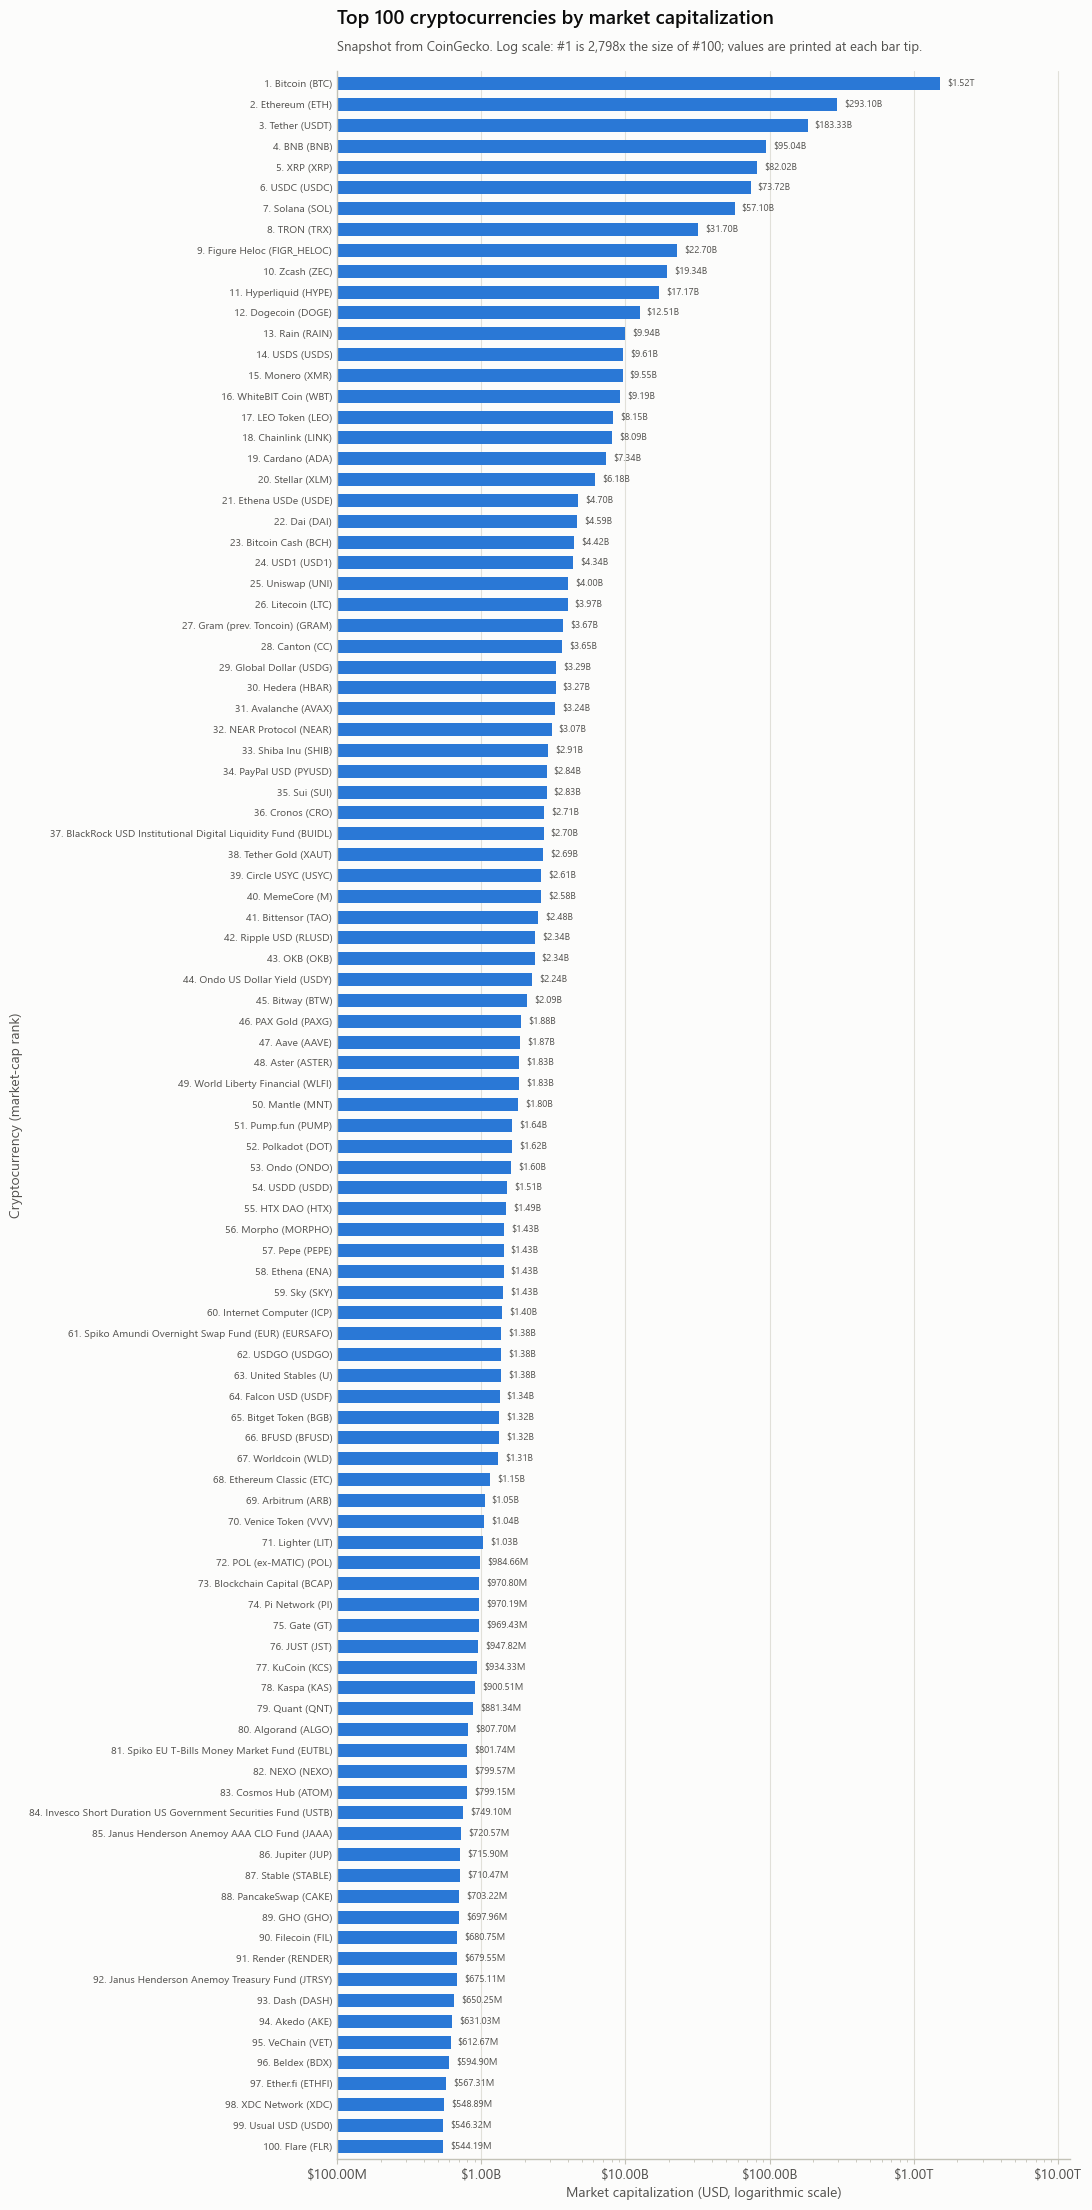

In [17]:
fig = viz.plot_market_cap(summary); None

### Graph 2 — Price trend (change `coin` to any coin id in the top 100)

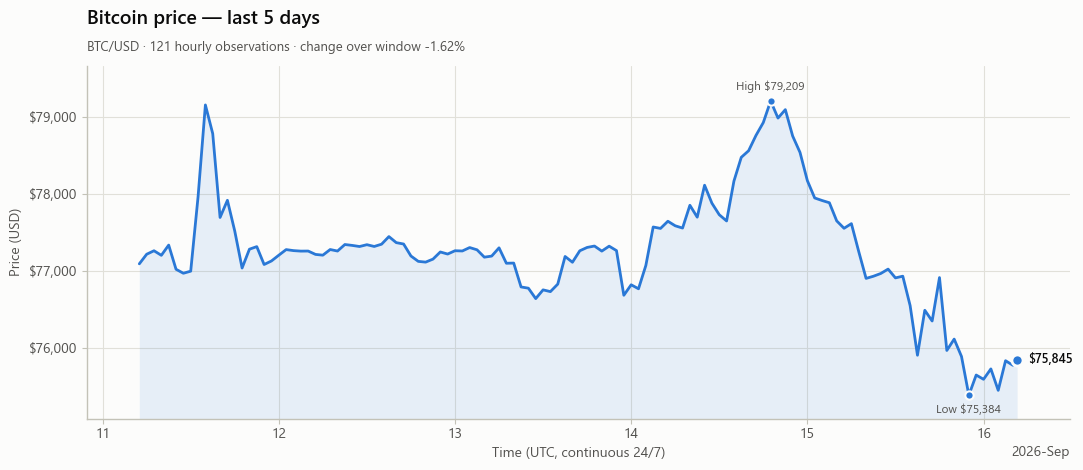

In [18]:
coin = result.selected_coins[0]
fig = viz.plot_price_trend(analysis, coin, cfg.days); None

### Graph 3 — Moving averages

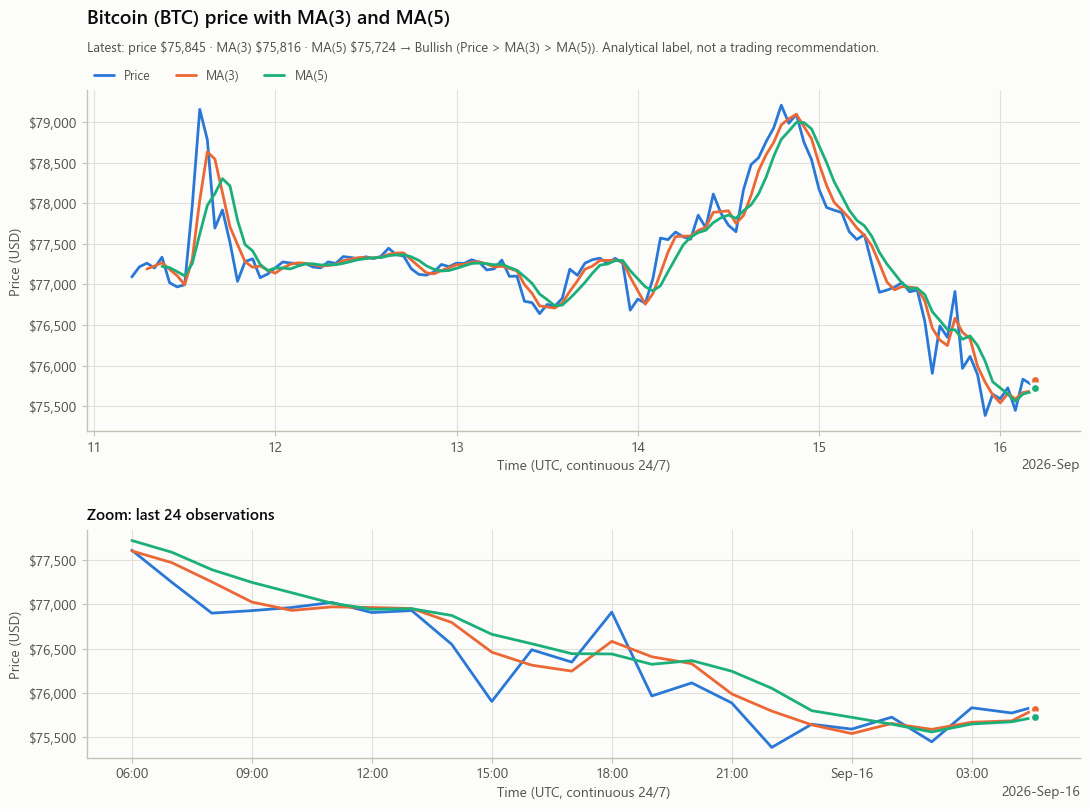

In [19]:
fig = viz.plot_moving_averages(analysis, coin, cfg.ma_windows); None

### Graph 4 — Volatility ranking

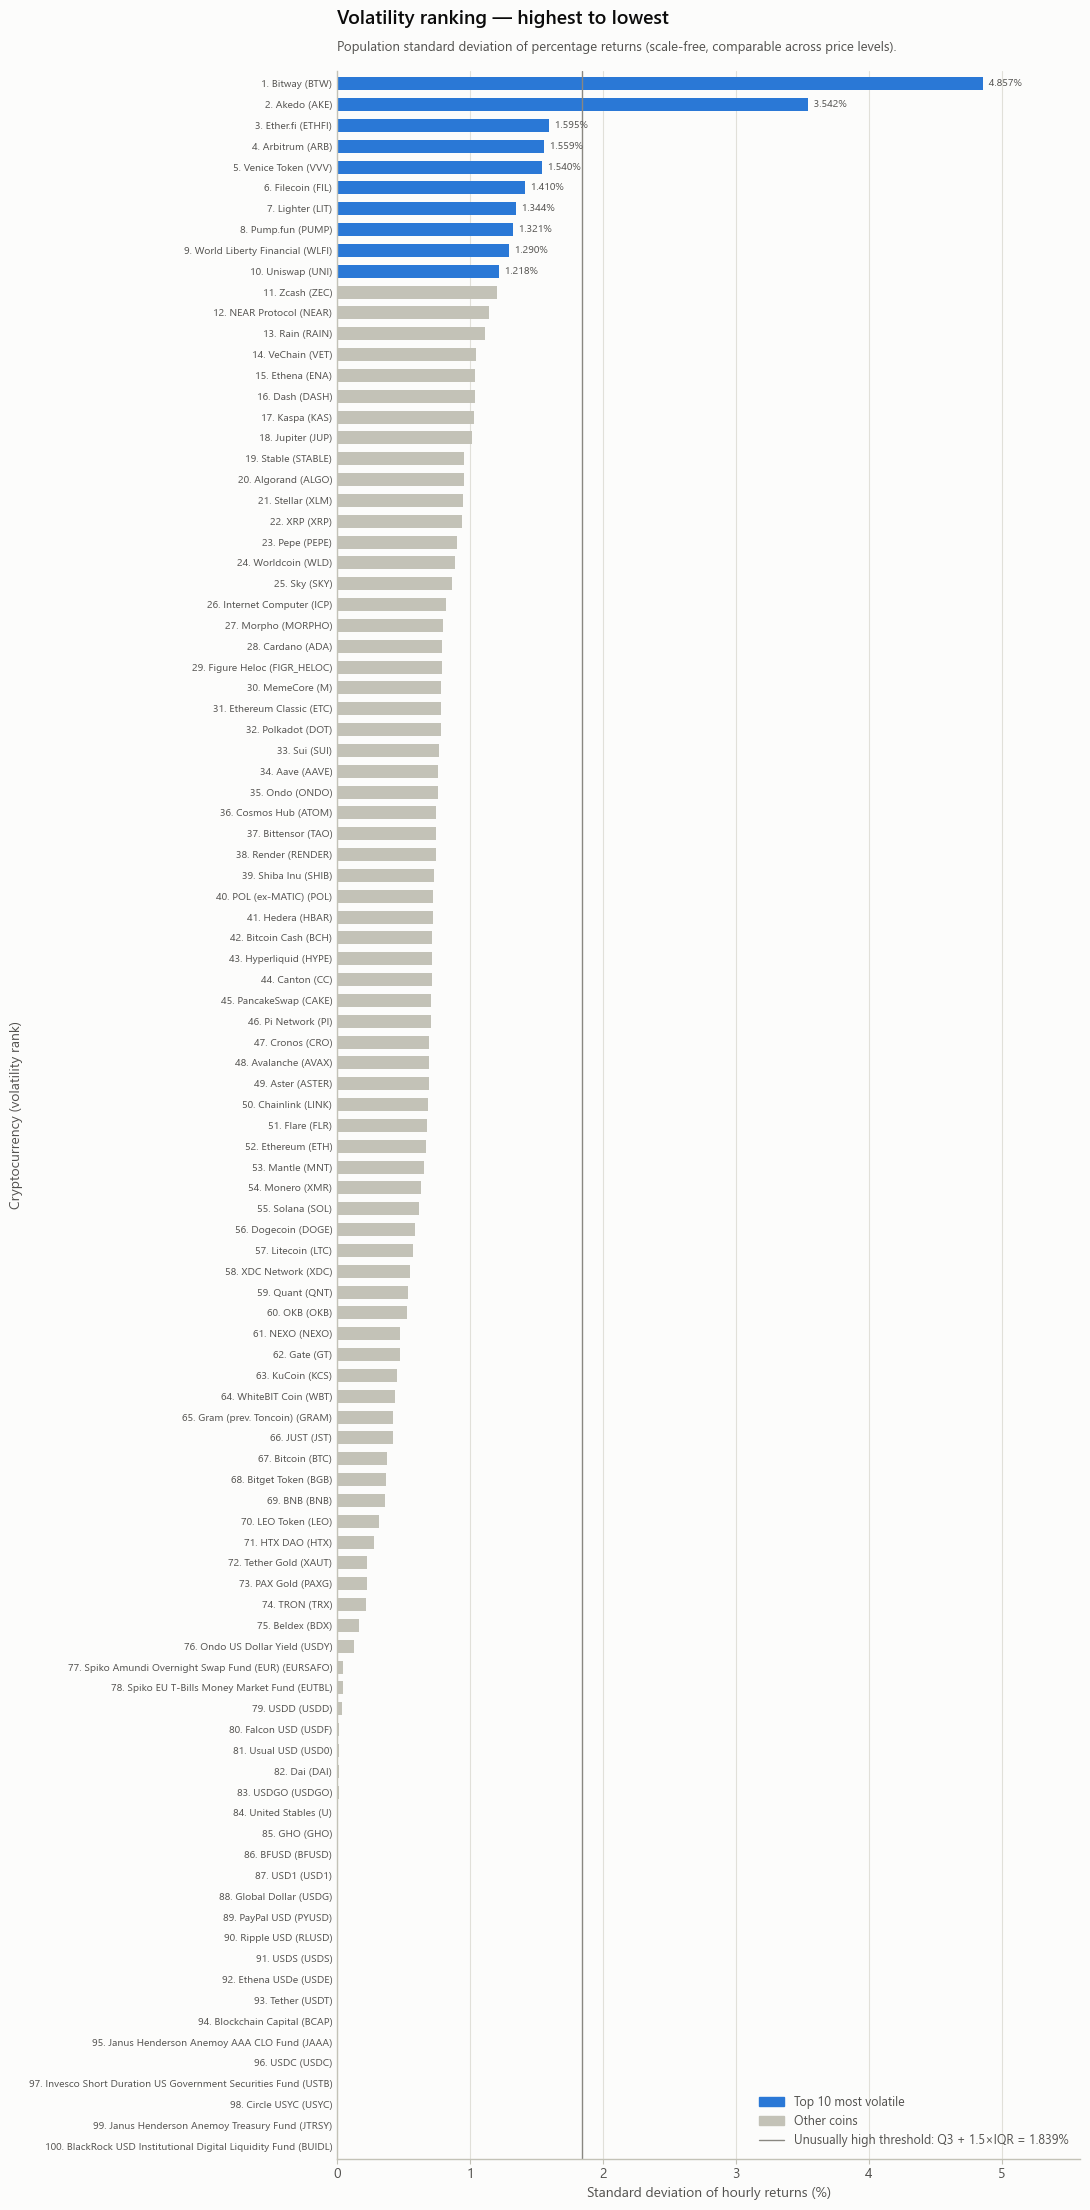

In [20]:
fig = viz.plot_volatility_ranking(summary, cfg.top_k, result.fence); None

### Graph 5 — Outlier detection

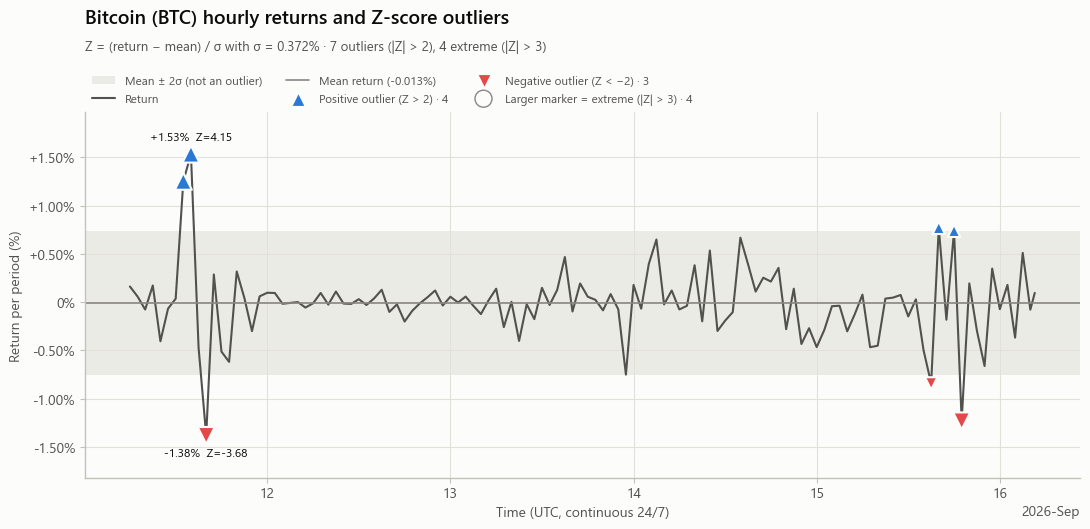

In [21]:
fig = viz.plot_outliers(analysis, coin, cfg.z_threshold, cfg.strict_z_threshold); None

### Graph 6 — Risk vs return

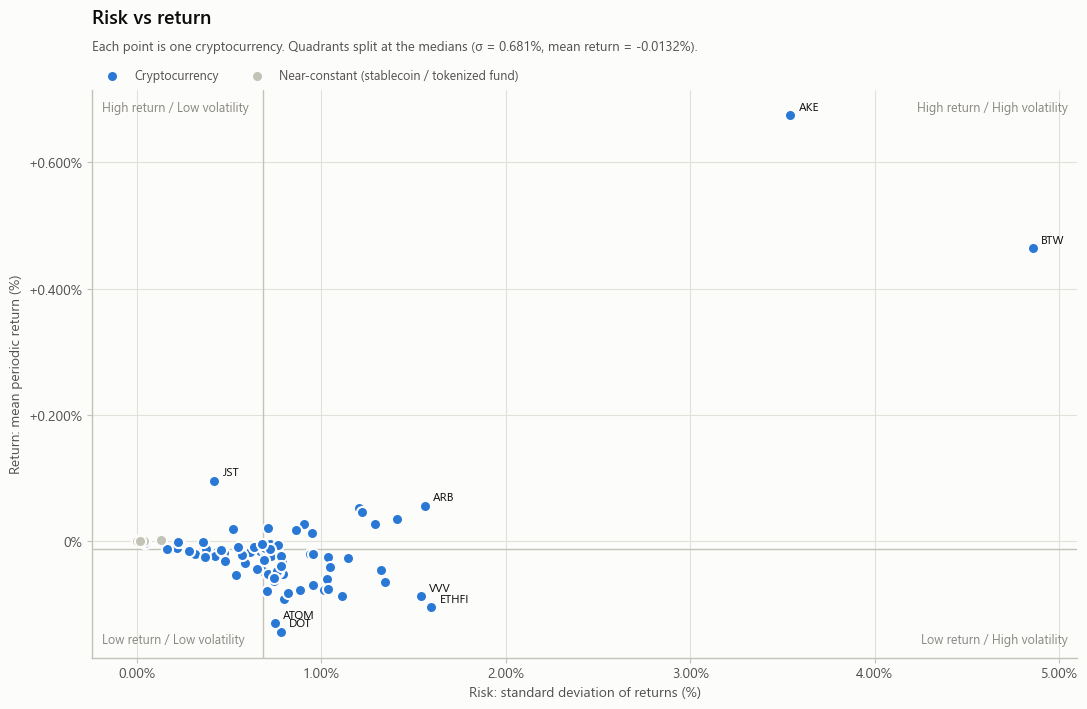

In [22]:
fig = viz.plot_risk_return(summary); None

Interactive versions (Plotly) are available too — useful for hovering individual observations:

In [23]:
viz.plotly_outlier_figure(analysis, coin, cfg.z_threshold)

## 8. Risk vs return

Quadrants split at the cross-sectional medians of standard deviation and mean return.

In [24]:
summary["risk_return_quadrant"].value_counts()

risk_return_quadrant
High return / Low volatility     36
Low return / High volatility     36
Low return / Low volatility      14
High return / High volatility    14
Name: count, dtype: int64

A supplementary multivariate check (scikit-learn `IsolationForest`) flags coins whose overall 5-day
behaviour is unusual across several features at once:

In [25]:
summary.loc[summary["is_anomalous_coin"], ["name", "symbol", "anomaly_score", "std_return_pct",
                                            "five_day_return_pct", "max_abs_return_pct",
                                            "max_drawdown_pct"]].sort_values("anomaly_score", ascending=False)

,name,symbol,anomaly_score,std_return_pct,five_day_return_pct,max_abs_return_pct,max_drawdown_pct
44,Bitway,BTW,0.818971,4.857220,51.143351,24.043477,-25.856350
93,Akedo,AKE,0.796879,3.541918,107.940114,15.442406,-17.162789
96,Ether.fi,ETHFI,0.618206,1.594932,-13.266455,5.831050,-24.268509
75,JUST,JST,0.593120,0.419804,11.906351,1.509210,-1.589718
68,Arbitrum,ARB,0.585104,1.559016,5.313094,8.712742,-12.327418


## 9. Key findings

In [26]:
reporting.print_console_summary(result.findings, cfg, result.fence, result.top_most,
                                result.top_least, result.outlier_report)


CRYPTOCURRENCY MARKET VOLATILITY & TREND ANALYSIS
Window: 2026-09-11 05:00 -> 2026-09-16 04:58 UTC | 100 coins | 12,066 observations | hourly data

KEY FINDINGS
  - Largest market cap: Bitcoin (BTC) at $1.52T.
  - Most volatile: Bitway (BTW) with σ = 4.857% per period (5-day return +51.14%).
  - Least volatile: BlackRock USD Institutional Digital Liquidity Fund (BUIDL) with σ = 0.0000% per period.
  - Highest 5-day return: Akedo (AKE) at +107.94%.
  - Lowest 5-day return: Polkadot (DOT) at -16.26%.
  - Breadth: 25 of 100 coins rose over the window; the median 5-day return was -1.73%.
  - Trend labels at the latest observation: Bullish 56 · Bearish 10 · Neutral 34.
  - Outliers (|Z| > 2): 614 of 11,846 returns (5.18%; a normal distribution implies ≈4.55%) — 303 positive, 311 negative.
  - Extreme outliers (|Z| > 3): 199 (1.68% vs ≈0.27% under normality), consistent with fat-tailed crypto returns.
  - Most outliers: OKB (OKB) with 10 (2 extreme).
  - Unusually high volatility (σ above Q

### Statistical summary table (sortable)

In [27]:
table = reporting.format_summary_table(reporting.sort_summary(summary, "volatility"), cfg.ma_windows)
table.head(20)

,Rank,Cryptocurrency,Symbol,Price (USD),5-Day Return (%),Mean Return (%),Std Dev (%),MA(3),MA(5),Trend,Outlier Count,Extreme Outliers,Volatility Rank,Market Cap (USD),Unusually High Volatility,Risk-Return Quadrant,USD-Pegged (heuristic),Near-Constant Asset,Isolation Forest Anomaly
0,45,Bitway,BTW,0.754582,51.143351,0.463700,4.857220,0.714487,0.702915,Bullish,7,5,1,2088019951,True,High return / High volatility,False,False,True
1,94,Akedo,AKE,0.027893,107.940114,0.674462,3.541918,0.028026,0.027763,Neutral,8,3,2,631034641,True,High return / High volatility,False,False,True
2,97,Ether.fi,ETHFI,0.586301,-13.266455,-0.105759,1.594932,0.587481,0.588176,Bearish,9,1,3,567308796,False,Low return / High volatility,False,False,True
3,69,Arbitrum,ARB,0.155517,5.313094,0.055102,1.559016,0.153191,0.151706,Bullish,6,2,4,1054038020,False,High return / High volatility,False,False,True
4,70,Venice Token,VVV,21.602602,-11.323100,-0.088316,1.539927,21.632529,21.529770,Neutral,4,1,5,1039769552,False,Low return / High volatility,False,False,False
5,90,Filecoin,FIL,0.816215,2.917212,0.033826,1.410028,0.814568,0.811490,Bullish,7,2,6,680747927,False,High return / High volatility,False,False,False
6,71,Lighter,LIT,4.119117,-8.487425,-0.064903,1.344418,4.095186,4.075481,Bullish,9,1,7,1031781311,False,Low return / High volatility,False,False,False
7,51,Pump.fun,PUMP,0.003496,-6.417578,-0.046582,1.320507,0.003469,0.003465,Bullish,6,2,8,1640960939,False,Low return / High volatility,False,False,False
8,49,World Liberty Financial,WLFI,0.057227,2.093488,0.025803,1.289574,0.057227,0.057122,Neutral,5,3,9,1825766209,False,High return / High volatility,False,False,False
9,25,Uniswap,UNI,6.456823,4.718264,0.045826,1.217620,6.362356,6.343821,Bullish,7,1,10,3996919750,False,High return / High volatility,False,False,False


## 9b. Accumulated history (SQLite)

Each run is appended to `data/crypto_market.db`. The API only serves a 5-day window, but the `prices`
table keeps every observation ever downloaded (keyed by coin and timestamp, so overlapping runs update
rather than duplicate). Running the pipeline regularly therefore builds a history longer than any single
fetch can return.

In [28]:
from src import database

with database.session(config.DATABASE_PATH) as conn:
    stored = database.totals(conn)
    history = database.run_history(conn)
    cover = database.coverage(conn)

print(f"Runs stored   : {stored['runs']}")
print(f"Observations  : {stored['observations']:,} for {stored['coins']} coins")
print(f"Days covered  : {stored['days_covered']:.2f} (a single API fetch returns {cfg.days})")
history.head()

Runs stored   : 3
Observations  : 12,066 for 100 coins
Days covered  : 5.00 (a single API fetch returns 5)


,run_id,started_at_utc,window_start_utc,window_end_utc,top_n,days,vs_currency,ma_short_window,ma_long_window,z_threshold,n_coins,n_observations,n_outliers,median_interval_minutes
0,3,2026-09-16 06:15:10,2026-09-11 05:00:00,2026-09-16 04:58:10,100,5,usd,3,5,2.0,100,12066,614,60.0
1,2,2026-09-16 06:13:08,2026-09-11 05:00:00,2026-09-16 04:58:10,100,5,usd,3,5,2.0,100,12066,614,60.0
2,1,2026-09-16 06:12:57,2026-09-11 05:00:00,2026-09-16 04:58:10,100,5,usd,3,5,2.0,100,12066,614,60.0


Accumulated history per coin:

In [29]:
cover.head(10)

,coin_id,symbol,name,observations,first_observation,last_observation,days_covered
0,aave,AAVE,Aave,121,2026-09-11 05:00:00,2026-09-16 04:46:20,4.99
1,akedo,AKE,Akedo,121,2026-09-11 05:00:00,2026-09-16 04:56:40,5.00
2,algorand,ALGO,Algorand,121,2026-09-11 05:00:00,2026-09-16 04:53:50,5.00
3,arbitrum,ARB,Arbitrum,121,2026-09-11 05:00:00,2026-09-16 04:51:20,4.99
4,aster-2,ASTER,Aster,121,2026-09-11 05:00:00,2026-09-16 04:46:20,4.99
5,avalanche-2,AVAX,Avalanche,121,2026-09-11 05:00:00,2026-09-16 04:42:30,4.99
6,beldex,BDX,Beldex,121,2026-09-11 05:00:00,2026-09-16 04:57:00,5.00
7,bfusd,BFUSD,BFUSD,121,2026-09-11 05:00:00,2026-09-16 04:50:40,4.99
8,binancecoin,BNB,BNB,121,2026-09-11 05:00:00,2026-09-16 04:35:20,4.98
9,bitcoin,BTC,Bitcoin,121,2026-09-11 05:00:00,2026-09-16 04:34:40,4.98


The stored data is plain SQL, so it can be queried directly — here the largest genuine moves,
excluding the near-constant assets discussed above:

In [30]:
import pandas as pd

query = '''
    SELECT c.name, c.symbol, o.timestamp_utc, ROUND(o.pct_return, 2) AS return_pct,
           ROUND(o.z_score, 2) AS z_score, o.outlier_type
    FROM outliers o JOIN coins c USING (coin_id)
    WHERE o.low_variation = 0
    ORDER BY ABS(o.z_score) DESC LIMIT 10
'''
with database.session(config.DATABASE_PATH) as conn:
    display(pd.read_sql_query(query, conn))

,name,symbol,timestamp_utc,return_pct,z_score,outlier_type
0,World Liberty Financial,WLFI,2026-09-11 11:00:00,-9.42,-7.33,Negative Outlier
1,Ethereum,ETH,2026-09-11 14:00:00,4.68,7.02,Positive Outlier
2,Rain,RAIN,2026-09-15 17:00:00,7.57,6.90,Positive Outlier
3,KuCoin,KCS,2026-09-11 13:00:00,2.79,6.20,Positive Outlier
4,LEO Token,LEO,2026-09-15 15:00:00,-1.94,-6.10,Negative Outlier
5,XRP,XRP,2026-09-15 19:00:00,-5.64,-5.98,Negative Outlier
6,Stellar,XLM,2026-09-15 19:00:00,-5.61,-5.92,Negative Outlier
7,WhiteBIT Coin,WBT,2026-09-11 14:00:00,2.40,5.59,Positive Outlier
8,Arbitrum,ARB,2026-09-15 16:00:00,8.71,5.55,Positive Outlier
9,Tether Gold,XAUT,2026-09-11 13:00:00,1.25,5.51,Positive Outlier


## 10. Methodology and limitations

**Formulas**

| Quantity | Formula |
|---|---|
| Periodic return | $r_t = (P_t - P_{t-1}) / P_{t-1} \times 100$ |
| 5-day return | $(P_{last} - P_{first}) / P_{first} \times 100$ |
| Moving average | $MA(k)_t = \frac{1}{k}\sum_{i=0}^{k-1} P_{t-i}$ |
| Standard deviation | $\sigma = \sqrt{\sum (x-\mu)^2 / N}$ |
| Z-score | $Z = (x - \mu) / \sigma$ |
| Annualised volatility | $\sigma \times \sqrt{\text{periods per year}}$, 365 × 24 hourly periods (24/7 market) |

**Limitations**

* Five days of hourly data is a short sample; statistics are noisy and regime-dependent.
* MA(3)/MA(5) on hourly observations describe hour-scale momentum only.
* Z-scores use each coin's own mean and σ, which are themselves inflated by the outliers (masking).
* Stablecoins have a near-zero σ, so trivial moves can produce large Z-scores — they are flagged `peg_like`.
* CoinGecko prices are cross-exchange aggregates; the final observation may cover a partial interval.

**Not financial advice** — this is a statistical description of past data.